In [ ]:
from keras.models import Sequential
from keras.layers import Dense,Conv2DTranspose,Conv2D,MaxPooling2D,BatchNormalization,Flatten,Dropout,LeakyReLU,Reshape
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os
from IPython import display
import time

# **Dataset Loading**

In [ ]:
(train_images,train_labels),(test_images,test_labels) = tf.keras.datasets.cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step


# **Scaling to -1 to 1**

In [ ]:
train_images = (train_images - 127.5)/127.5

# **Convert dataset to tensorflow dataset and shuffling by batchsize**

In [ ]:
BUFFER_SIZE = 70000
BATCH_SIZE  = 256

In [ ]:
train_dataset = tf.data.Dataset.from_tensor_slices(tensors=train_images).shuffle(buffer_size=BUFFER_SIZE).batch(batch_size=BATCH_SIZE)

# **Generator**

In [ ]:
def Make_Generator():

    model = Sequential()

    model.add(Dense(units=8*8*256,use_bias=False, input_shape=(100,)))
    model.add(BatchNormalization())
    model.add(LeakyReLU())

    model.add(Reshape(target_shape=(8,8,256)))
    assert model.output_shape == (None,8,8,256)


    model.add(Conv2DTranspose(filters=128, kernel_size=(5, 5), strides=(1, 1), padding='same', use_bias=False))
    assert model.output_shape == (None, 8, 8, 128)
    model.add(BatchNormalization())
    model.add(LeakyReLU())

    model.add(Conv2DTranspose(filters=64, kernel_size=(5, 5), strides=(2, 2), padding='same', use_bias=False))
    assert model.output_shape == (None, 16, 16, 64)
    model.add(BatchNormalization())
    model.add(LeakyReLU())

    model.add(Conv2DTranspose(filters=3, kernel_size=(5, 5), strides=(2, 2), padding='same', use_bias=False, activation='tanh'))
    assert model.output_shape == (None, 32, 32, 3)

    return model

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


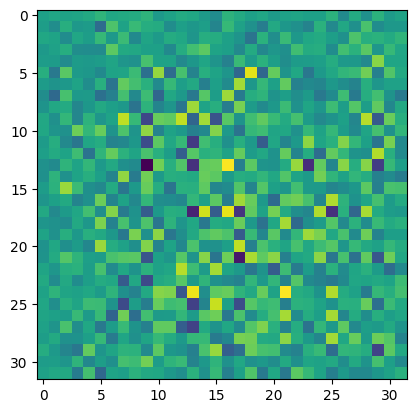

In [ ]:
generator = Make_Generator()
noise = tf.random.normal(shape=[1,100])
generated = generator(noise,training=False)

plt.imshow(generated[0,:,:,0])

# **discriminator**

In [ ]:
def Make_Discriminator():

    model = tf.keras.Sequential()
    model.add(Conv2D(filters=64, kernel_size=(5, 5), strides=(2, 2), padding='same',
                                     input_shape=[32, 32, 3]))
    model.add(LeakyReLU())
    model.add(Dropout(rate=0.3))

    model.add(Conv2D(filters=128, kernel_size=(5, 5), strides=(2, 2), padding='same'))
    model.add(LeakyReLU())
    model.add(Dropout(rate=0.3))

    model.add(Flatten())
    model.add(Dense(units=3))

    return model

In [ ]:
discriminator = Make_Discriminator()
decision = discriminator(generated)
print (decision)

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


tf.Tensor([[ 0.00072846 -0.00214809 -0.00023889]], shape=(1, 3), dtype=float32)


# **BinaryCrossEntropy**

In [ ]:
cross_entropy =  tf.keras.losses.BinaryCrossentropy(from_logits=True)

# **Discriminator loss**

In [ ]:
def discriminator_loss(real_output,fake_output):

    real_loss = cross_entropy(tf.ones_like(real_output),real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output),fake_output)
    total_loss = real_loss + fake_loss

    return total_loss

# **Generator Loss**

In [ ]:
def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output),fake_output)

# **Discriminator Optimizer and Generator Optimizer**

In [ ]:
discriminator_optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4)
generator_optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4)

# **Checkpoints**

In [ ]:
checkpoin_path = "./training_Arguments"
checkpoint_prefix = os.path.join(checkpoin_path,'ckpt')
checkpoint = tf.train.Checkpoint(generator_optimizer=generator_optimizer,
                                 discriminator_optimizer=discriminator_optimizer,
                                 generator=generator,
                                 discriminator=discriminator)

In [ ]:
EPOCHS = 30
noise_dim = 100
num_examples_to_generate = 16

seed = tf.random.normal([num_examples_to_generate, noise_dim])

In [ ]:
# Notice the use of `tf.function`
# This annotation causes the function to be "compiled".
@tf.function
def train_step(images):
    noise = tf.random.normal([BATCH_SIZE, noise_dim])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
      generated_images = generator(noise, training=True)

      real_output = discriminator(images, training=True)
      fake_output = discriminator(generated_images, training=True)

      gen_loss = generator_loss(fake_output)
      disc_loss = discriminator_loss(real_output, fake_output)

    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

In [ ]:
def generate_and_save_images(model, epoch, test_input):
  # Notice `training` is set to False.
  # This is so all layers run in inference mode (batchnorm).
  predictions = model(test_input, training=False)

  fig = plt.figure(figsize=(4, 4))

  for i in range(predictions.shape[0]):
      plt.subplot(4, 4, i+1)
      plt.imshow(predictions[i, :, :, 0] * 127.5 + 127.5)
      plt.axis('off')

  plt.savefig('image_at_epoch_{:04d}.png'.format(epoch))
  plt.show()

In [ ]:
def train(training_dataset,epochs):

    for epoch in range(epochs):
        start = time.time()

        for image_batch in train_dataset:
            train_step(image_batch)
        display.clear_output(wait=True)
        generate_and_save_images(generator,
                             epoch + 1,
                             seed)
        if (epoch + 1) % 15 == 0:
            checkpoint.save(file_prefix = checkpoint_prefix)

        print ('Time for epoch {} is {} sec'.format(epoch + 1, time.time()-start))

    display.clear_output(wait=True)
    generate_and_save_images(generator,
                           epochs,
                           seed)

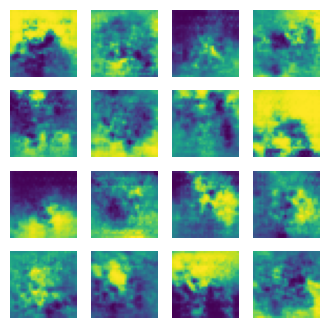

In [ ]:
with tf.device('/device:GPU:0'):
  train(train_dataset, EPOCHS)

In [ ]:
checkpoint.restore(tf.train.latest_checkpoint(checkpoin_path))

In [ ]:
import shutil


folder_path = "/content/training_Arguments"

shutil.make_archive("/content/training_Arguments", 'zip', folder_path)

Checkpoint restored from: ./training_Arguments/ckpt-10


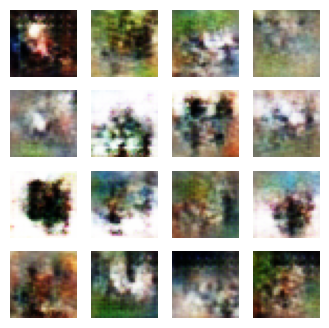

In [ ]:

import tensorflow as tf
import matplotlib.pyplot as plt

# Function to define the generator model (same as during training)
def Make_Generator():
    model = tf.keras.Sequential()
    model.add(tf.keras.layers.Dense(8 * 8 * 256, use_bias=False, input_shape=(100,)))
    model.add(tf.keras.layers.BatchNormalization())
    model.add(tf.keras.layers.LeakyReLU())

    model.add(tf.keras.layers.Reshape((8, 8, 256)))
    model.add(tf.keras.layers.Conv2DTranspose(128, (5, 5), strides=(1, 1), padding='same', use_bias=False))
    model.add(tf.keras.layers.BatchNormalization())
    model.add(tf.keras.layers.LeakyReLU())

    model.add(tf.keras.layers.Conv2DTranspose(64, (5, 5), strides=(2, 2), padding='same', use_bias=False))
    model.add(tf.keras.layers.BatchNormalization())
    model.add(tf.keras.layers.LeakyReLU())

    model.add(tf.keras.layers.Conv2DTranspose(3, (5, 5), strides=(2, 2), padding='same', use_bias=False, activation='tanh'))
    return model

# Define the generator
generator = Make_Generator()

# Define the checkpoint directory
checkpoint_path = "./training_Arguments"
checkpoint = tf.train.Checkpoint(generator=generator)

# Restore the checkpoint if it exists
latest_checkpoint = tf.train.latest_checkpoint(checkpoint_path)
if latest_checkpoint:
    checkpoint.restore(latest_checkpoint).expect_partial()
    print(f"Checkpoint restored from: {latest_checkpoint}")
else:
    print("No checkpoint found. Train the model first.")

# Function to generate and visualize images
def generate_images(generator, num_images=16, noise_dim=100):
    noise = tf.random.normal([num_images, noise_dim])  # Generate random noise
    generated_images = generator(noise, training=False)  # Generate images

    # Rescale images from [-1, 1] to [0, 1] for visualization
    generated_images = (generated_images + 1) / 2.0

    # Plot the images
    fig = plt.figure(figsize=(4, 4))
    for i in range(num_images):
        plt.subplot(4, 4, i + 1)
        plt.imshow(generated_images[i])
        plt.axis('off')
    plt.show()

# Generate and visualize 16 images
generate_images(generator, num_images=16)

In [ ]:
from google.colab import files
files.download("/content/training_Arguments.zip")

In [ ]:

import tensorflow as tf
import matplotlib.pyplot as plt

# Function to define the generator model (same as training)
def Make_Generator():
    model = tf.keras.Sequential()
    model.add(tf.keras.layers.Dense(8 * 8 * 256, use_bias=False, input_shape=(100,)))
    model.add(tf.keras.layers.BatchNormalization())
    model.add(tf.keras.layers.LeakyReLU())

    model.add(tf.keras.layers.Reshape((8, 8, 256)))
    model.add(tf.keras.layers.Conv2DTranspose(128, (5, 5), strides=(1, 1), padding='same', use_bias=False))
    model.add(tf.keras.layers.BatchNormalization())
    model.add(tf.keras.layers.LeakyReLU())

    model.add(tf.keras.layers.Conv2DTranspose(64, (5, 5), strides=(2, 2), padding='same', use_bias=False))
    model.add(tf.keras.layers.BatchNormalization())
    model.add(tf.keras.layers.LeakyReLU())

    model.add(tf.keras.layers.Conv2DTranspose(3, (5, 5), strides=(2, 2), padding='same', use_bias=False, activation='tanh'))
    return model

# Define the generator
generator = Make_Generator()

# Define the checkpoint directory
checkpoint_path = "./training_Arguments"
checkpoint = tf.train.Checkpoint(generator=generator)

# Restore the checkpoint
latest_checkpoint = tf.train.latest_checkpoint(checkpoint_path)
if latest_checkpoint:
    checkpoint.restore(latest_checkpoint).expect_partial()
    print(f"Checkpoint restored from: {latest_checkpoint}")
else:
    print("No checkpoint found. Train the model first.")

# Function to generate and visualize images
def generate_images(generator, num_images=16, noise_dim=100):
    noise = tf.random.normal([num_images, noise_dim])  # Generate random noise
    generated_images = generator(noise, training=False)  # Generate images

    # Rescale images from [-1, 1] to [0, 1] for visualization
    generated_images = (generated_images + 1) / 2.0

    # Plot the images
    fig = plt.figure(figsize=(4, 4))
    for i in range(num_images):
        plt.subplot(4, 4, i + 1)
        plt.imshow(generated_images[i])
        plt.axis('off')
    plt.show()

# Generate and visualize 16 images
generate_images(generator, num_images=16)